# YodaX: do more relevant events make better forecasts?

The first experiment gave Apple and Freeport-McMoRan the same global event counts. Both adjustment models performed worse than TimesFM. That was a useful warning: a larger pile of news is not necessarily better information.

This version asks a more specific question. If we connect events to countries where each company says it has manufacturing or mining operations, does that help? We use dated company disclosures, keep the model settings fixed, and compare market-only, global-event and country-linked models on the same dates.

The default `exposure_study` uses real data and two longer validation periods. It still covers two companies, not all 20. `real_check` retains the earlier short experiment; `real` is the full-study configuration; `synthetic_verification` only checks the software. None of these modes changes production forecasts.

The results below determine the conclusion. Country relevance is a hypothesis about economic exposure, not proof of causation.

In [1]:
import os, sys, json
from pathlib import Path
from datetime import datetime, timezone
ROOT = Path.cwd()
if not (ROOT / 'research_pipeline').exists():
    ROOT = ROOT.parent
assert (ROOT / 'research_pipeline').exists(), 'Open from the repository or notebooks folder'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from research_pipeline.collect import collect_prices, collect_events, write_json
from research_pipeline.features import build_features, MARKET_FEATURES, EVENT_FEATURES
from research_pipeline.evaluate import chronological_split, summarize
from research_pipeline.model import load_bundle
from research_pipeline.__main__ import run_experiment
MODE = os.environ.get('YODAX_NOTEBOOK_MODE', 'exposure_study')
assert MODE in {'real', 'real_check', 'synthetic_verification', 'exposure_study'}
CONFIG = json.loads((ROOT / 'config/research.json').read_text())
DATA = ROOT / 'data' / {'exposure_study':'research-exposure-study', 'real':'research', 'real_check':'research-real-check', 'synthetic_verification':'notebook-fixture'}[MODE]
RUN = ROOT / 'data/research-runs' / ('notebook-' + MODE + '-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
print('Mode:', MODE, '\nDataset:', DATA, '\nOutput:', RUN)

Mode: exposure_study 
Dataset: /Users/sumitsharma/Documents/ChatGPT/YodaX/data/research-exposure-study 
Output: /Users/sumitsharma/Documents/ChatGPT/YodaX/data/research-runs/notebook-exposure_study-20261023T111657803314Z


## 1. What have we collected?

We have daily price histories for the 20-stock watchlist, plus SPY and three oil/copper futures series. Separately, we downloaded a sample of GDELT's daily event archives. The cells below show the actual coverage; having prices from 2015 does not mean we have event data for that whole period.

GDELT records reported interactions between actors. For this first pass, we use its broad cooperation and conflict categories. That is a rough measure of news activity. It does not tell us how much copper production was lost, which company depends on a particular supplier, or whether an FTA has taken effect.

Silicon, lithium and steel price histories still need suitable benchmarks and sources. We have not filled those gaps with related company stocks.

The collection switches are off so reopening the notebook does not start a large download. Cached source files and hashes let us inspect what we used later.

For the new study, Apple’s 2024 annual filing supplies a list of principal outsourced-manufacturing countries. Freeport’s filing supplies mining-operation countries. The registry records the source, filing date and conservative date from which we allow it into a forecast. A later disclosure cannot be applied retroactively.

These are binary links. We do not assume equal economic exposure or invent percentages. The snapshot is carried forward for at most 730 days; its age is included so we can inspect staleness. We still need better historical exposure measurements before making stronger claims.

In [2]:
COLLECT_PRICES = False
COLLECT_EVENTS = False
EVENT_START, EVENT_END = '2026-04-15', '2026-10-22'  # end exclusive; deliberate bounded example
if MODE == 'real' and COLLECT_PRICES:
    collect_prices(CONFIG['stocks'] + CONFIG['market_context'], CONFIG['start'],
                   str(pd.Timestamp.now(tz='UTC').date()), DATA)
if MODE == 'real' and COLLECT_EVENTS:
    collect_events(EVENT_START, EVENT_END, DATA, CONFIG['event_lag_days'])
if MODE == 'synthetic_verification':
    from research_pipeline.fixtures import synthetic_inputs
    DATA.mkdir(parents=True, exist_ok=True)
    for frame, name in zip(synthetic_inputs(), ['prices','events','baselines']):
        frame.to_parquet(DATA / f'{name}.parquet', index=False)
    CONFIG.update(stocks=['AAPL','FCX'], validation_windows=[['2021-01-01','2022-01-01'], ['2022-01-01','2023-01-01']], holdout_start='2023-01-01')
elif MODE == 'exposure_study':
    CONFIG = json.loads((ROOT/'config/research-exposure-study.json').read_text())
elif MODE == 'real_check':
    assert (DATA/'config.json').exists(), 'Prepare the real check as described in docs/research-pipeline.md, or select synthetic_verification.'
    CONFIG = json.loads((DATA/'config.json').read_text())
print('Requested commodity coverage:')
display(pd.Series(CONFIG['coverage_notes'], name='status').to_frame())
coverage_path = ROOT/'data/research/price_coverage.json'
if coverage_path.exists():
    display(pd.DataFrame(json.loads(coverage_path.read_text()))[['symbol','status','first','last','rows']])
if CONFIG.get('exposure_registry'):
    display(pd.DataFrame(CONFIG['exposure_registry']['snapshots'])[['symbol','countries','exposure_type','filing_date','available_at','source_url']])

Requested commodity coverage:


,status
oil,Yahoo front-month WTI/Brent futures proxies; n...
copper,Yahoo front-month copper futures proxy; roll e...
silicon,Not collected: silicon metal vs polysilicon be...
lithium,"Not collected: grade, region and licensed hist..."
steel,Not collected: regional HRC benchmark and lice...


,symbol,status,first,last,rows
0,AAPL,collected,2015-01-02,2026-10-21,2968
1,MSFT,collected,2015-01-02,2026-10-21,2968
2,GOOGL,collected,2015-01-02,2026-10-21,2968
3,AMZN,collected,2015-01-02,2026-10-21,2968
4,NVDA,collected,2015-01-02,2026-10-21,2968
5,META,collected,2015-01-02,2026-10-21,2968
6,JPM,collected,2015-01-02,2026-10-21,2968
7,BAC,collected,2015-01-02,2026-10-21,2968
8,GS,collected,2015-01-02,2026-10-21,2968
9,JNJ,collected,2015-01-02,2026-10-21,2968


,symbol,countries,exposure_type,filing_date,available_at,source_url
0,AAPL,"[CHN, IND, JPN, KOR, TWN, VNM]",outsourced_manufacturing,2024-11-01,2024-11-04T00:00:00Z,https://www.sec.gov/Archives/edgar/data/320193...
1,FCX,"[USA, PER, CHL, IDN]",mining_operations,2025-02-14,2025-03-01T00:00:00Z,https://www.sec.gov/Archives/edgar/data/831259...


## 2. Check the inputs before making features

First, check the dates, repeated rows and missing trading sessions. A file can contain thousands of rows and still be unsuitable for the question we want to answer.

These are downloaded vendor histories, not price feeds archived on each original date. Their past values may have been restated. Our target is a closing-price return, not total shareholder return including dividends.

The oil and copper series are front-month futures proxies. Contract changes can move these series, so they need more work before we treat every movement as an economic signal. The audit below checks basic completeness; it cannot verify every price against an independent provider.

In [3]:
prices = pd.read_parquet(DATA/'prices.parquet')
event_path = DATA/('events-enriched.parquet' if CONFIG.get('exposure_registry') else 'events.parquet')
events = pd.read_parquet(event_path) if event_path.exists() else None
display(prices.groupby('symbol').agg(first=('date','min'), last=('date','max'), observations=('date','size')))
print('Duplicate price keys:', prices.duplicated(['symbol','date']).sum())
print('Available event archive days:', 0 if events is None else len(events))
if events is not None:
    display(events.head(3))

,first,last,observations
symbol,,,
AAPL,2023-11-01,2026-10-21,745
CL=F,2023-11-01,2026-10-20,746
FCX,2023-11-01,2026-10-21,745
HG=F,2023-11-01,2026-10-21,748
SPY,2023-11-01,2026-10-21,745


Duplicate price keys: 0
Available event archive days: 641


,archive_day,available_at,verbal_cooperation,material_cooperation,verbal_conflict,material_conflict,event_total,6e9ff7c1f9ef3511_total,6e9ff7c1f9ef3511_conflict,6e9ff7c1f9ef3511_sanctions,6e9ff7c1f9ef3511_incoming_sanctions,6e9ff7c1f9ef3511_cooperation,6e9ff7c1f9ef3511_negotiation_halt,be14b9f4dc458834_total,be14b9f4dc458834_conflict,be14b9f4dc458834_sanctions,be14b9f4dc458834_incoming_sanctions,be14b9f4dc458834_cooperation,be14b9f4dc458834_negotiation_halt
0,2025-01-01,2025-01-03 00:00:00+00:00,42815,8256,8537,11599,71207,5815,782,9,2,627,2,19017,3266,78,3,2152,11
1,2025-01-02,2025-01-04 00:00:00+00:00,54336,11442,11180,14674,91632,6987,1069,18,8,963,7,24781,4144,22,3,3072,9
2,2025-01-03,2025-01-05 00:00:00+00:00,63140,12659,13765,16931,106495,7665,1090,65,41,977,0,30563,4951,63,23,3600,15


In [4]:
from research_pipeline.features import calendar_for
calendar = calendar_for(prices, CONFIG['horizon'])
quality_rows = []
for symbol in CONFIG['stocks']:
    frame = prices[prices.symbol == symbol].copy()
    expected = calendar.sessions_in_range(frame.date.min(), frame.date.max()).tz_localize(None)
    observed = pd.DatetimeIndex(frame.date)
    quality_rows.append({
        'symbol': symbol, 'rows': len(frame),
        'missing_exchange_sessions': len(expected.difference(observed)),
        'duplicate_dates': frame.date.duplicated().sum(),
        'invalid_close_rows': ((frame.close <= 0) | ~np.isfinite(frame.close)).sum(),
        'zero_volume_rows': frame.volume.eq(0).sum(),
        'split_days': frame.split.ne(0).sum()
    })
display(pd.DataFrame(quality_rows))
print('These checks measure completeness and validity, not independent price accuracy or causal relevance.')

,symbol,rows,missing_exchange_sessions,duplicate_dates,invalid_close_rows,zero_volume_rows,split_days
0,AAPL,745,0,0,0,0,0
1,FCX,745,0,0,0,0,0


These checks measure completeness and validity, not independent price accuracy or causal relevance.


## 3. Get the starting forecast from TimesFM

TimesFM is already pretrained. We do not retrain it here. For each forecast date, we give it the previous 256 closing prices and ask for the fifth future session's price. We convert that into a return relative to the current close.

The forecasts are cached with their input hashes, horizon and model revision. This avoids repeating the expensive step when we change the adjustment model.

There is a limitation we cannot resolve from this notebook: we do not know whether TimesFM's original training data overlaps these historical periods. Keeping each input window in the past prevents one kind of leakage, but does not establish that the foundation model has never seen the period. Forecasts saved before real outcomes arrive will be needed too.

In [5]:
GENERATE_BASELINES = False  # full study is a substantial CPU job; see CLI command
if MODE == 'real' and GENERATE_BASELINES:
    from research_pipeline.baseline import timesfm_baselines
    timesfm_baselines(prices, CONFIG, DATA)
assert (DATA/'baselines.parquet').exists(), 'Run the baseline CLI first, using the TimesFM environment.'
baselines = pd.read_parquet(DATA/'baselines.parquet')
print('Baseline revisions:', baselines.model_revision.unique().tolist())
print('Forecasts:', len(baselines))

Baseline revisions: ['1d952420fba87f3c6dee4f240de0f1a0fbc790e3']
Forecasts: 980


## 4. Turn the inputs into features

We retain the nine market features and the global event columns so we can compare with the earlier approach. The new model also receives country-linked event volume, conflict and cooperation shares, reported sanctions/embargoes/boycotts, sanctions directed at a relevant country, halted negotiations, and the age of the disclosure.

An event is counted once for a company even if both actors are in its country list. The direction matters for sanctions: a relevant country issuing a sanction is different from that country receiving it. The CAMEO category for halted negotiations is not an FTA implementation classifier.

This makes the features different for Apple and Freeport, but it is still a rough relevance filter. An event involving China does not necessarily affect Apple, and a report about Peru does not necessarily affect copper production. The audit records missing country codes and source links; it does not establish independent corroboration.

We align prices to trading sessions, reject affected split/missing-price windows, and only use event archives available under the two-day replay delay. Country snapshots must also be available and within their age limit. Missing archives never become zero events.

Feature rows: 980 | Settled targets: 970
Complete event coverage: 88.0%


,symbol,date,target_date,baseline_return,target_return
975,FCX,2026-10-19,2026-10-26,-0.010526,NaN
976,AAPL,2026-10-20,2026-10-27,-0.005283,NaN
977,FCX,2026-10-20,2026-10-27,-0.016369,NaN
978,AAPL,2026-10-21,2026-10-28,-0.006344,NaN
979,FCX,2026-10-21,2026-10-28,-0.017615,NaN


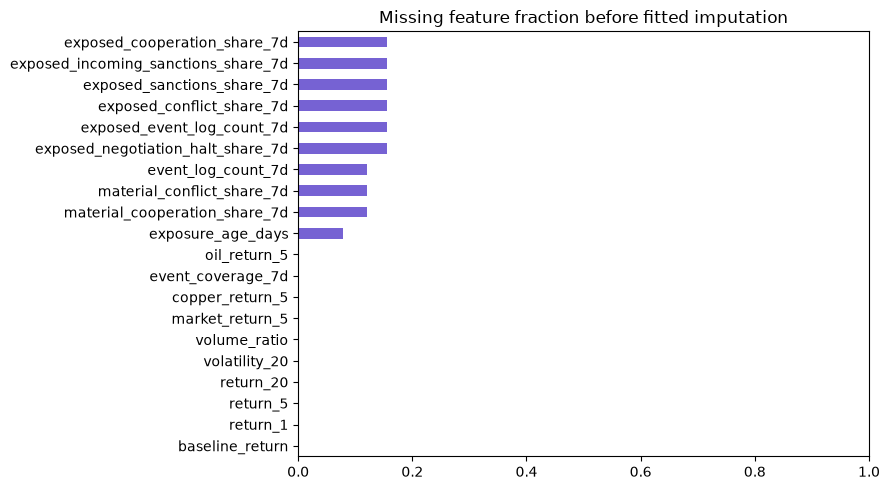

In [6]:
features = build_features(prices, events, baselines, CONFIG)
from research_pipeline.features import model_event_features
columns = MARKET_FEATURES + model_event_features(CONFIG)
print('Feature rows:', len(features), '| Settled targets:', features.target_return.notna().sum())
print('Complete event coverage:', f'{features.event_coverage_7d.eq(1).mean():.1%}')
display(features[['symbol','date','target_date','baseline_return','target_return']].tail())
missing = features[columns].isna().mean().sort_values()
ax = missing.plot.barh(figsize=(9,5), color='#7662d3', title='Missing feature fraction before fitted imputation')
ax.set_xlim(0,1); plt.tight_layout(); plt.show()

## 5. Keep training and evaluation separate

We train on earlier dates and remove labels whose outcomes reach into the evaluation period. All companies use the same time boundaries. Imputation is fitted on training rows only.

The exposure study evaluates September–December 2025 and January–June 2026. The model settings were fixed before inspecting these results. The second fold trains on more history than the first.

July 2026 onward is excluded here, but it overlaps the earlier exploratory check. We must not call it an untouched holdout. A genuinely prospective period is still needed before a production decision.

In [7]:
eligible = features[features.event_coverage_7d.eq(1)]
if CONFIG.get('exposure_registry'):
    eligible = eligible[eligible.exposure_known.eq(1) & eligible.exposure_coverage_7d.eq(1)]
splits = []
for start, end in CONFIG['validation_windows']:
    train, test = chronological_split(eligible, start, end)
    assert train.target_date.max() < test.date.min()
    splits.append({'train_start':train.date.min(), 'last_train_target':train.target_date.max(),
                   'test_start':test.date.min(), 'test_end':test.date.max(),
                   'train_rows':len(train), 'test_rows':len(test)})
display(pd.DataFrame(splits))

,train_start,last_train_target,test_start,test_end,train_rows,test_rows
0,2025-01-10,2025-08-29,2025-09-02,2025-12-23,244,160
1,2025-01-10,2025-12-31,2026-01-02,2026-06-23,414,236


### How informative are these features?

The next table is an initial diagnostic, using training data only. It shows missing values, distinct values and the Spearman association with the future return. A constant feature has nothing to teach this model. A large association deserves investigation; it is not evidence that the feature causes the return.

The rows are dependent: event values repeat across stocks, and five-session targets overlap across dates. We therefore do not attach ordinary independent-sample p-values to this table. We also do not automatically select features from these correlations.

In [8]:
audit_train, _ = chronological_split(eligible, *CONFIG['validation_windows'][-1])
audit = pd.DataFrame({
    'missing_fraction': audit_train[columns].isna().mean(),
    'distinct_values': audit_train[columns].nunique(),
    'constant_or_empty': audit_train[columns].nunique().le(1),
    'training_spearman_with_return': audit_train[columns + ['target_return']].corr(method='spearman')['target_return'].drop('target_return')
})
display(audit.round(4))
shared_events = audit_train.groupby('date')[model_event_features(CONFIG)].nunique().le(1).all()
print('Which event columns still have identical values across companies on every date?')
display(shared_events.to_frame('shared'))
print('Training observations:', len(audit_train), '| Distinct training dates:', audit_train.date.nunique())

,missing_fraction,distinct_values,constant_or_empty,training_spearman_with_return
baseline_return,0.0,414,False,0.0607
return_1,0.0,413,False,-0.0137
return_5,0.0,414,False,-0.1405
return_20,0.0,414,False,-0.2323
volatility_20,0.0,414,False,0.1348
volume_ratio,0.0,414,False,-0.0000
market_return_5,0.0,224,False,-0.1519
oil_return_5,0.0,224,False,-0.1034
copper_return_5,0.0,224,False,-0.0739
event_log_count_7d,0.0,224,False,-0.0958


Which event columns still have identical values across companies on every date?


,shared
event_log_count_7d,True
material_conflict_share_7d,True
material_cooperation_share_7d,True
event_coverage_7d,True
exposed_event_log_count_7d,False
exposed_conflict_share_7d,False
exposed_sanctions_share_7d,False
exposed_incoming_sanctions_share_7d,False
exposed_cooperation_share_7d,False
exposed_negotiation_halt_share_7d,False


Training observations: 414 | Distinct training dates: 224


## 6. Fit the adjustment models

Each model learns TimesFM’s forecast error and adds its estimated correction to the original prediction. The shallow trees, regularization and seed are unchanged from the first experiment.

The country-linked study compares five forecasts: no change, TimesFM, market-only adjustment, adjustment with global events, and adjustment with global plus country-linked events. They use exactly the same eligible rows. Comparing the last two tests the extra country information; comparing against market-only tests the overall event addition.

This is still exploratory validation. We do not keep changing settings until a particular period looks favorable. Every run saves its configuration, predictions, source hashes and dataset audit.

{
  "output": "/Users/sumitsharma/Documents/ChatGPT/YodaX/data/research-runs/notebook-exposure_study-20261023T111657803314Z",
  "folds": [
    {
      "start": "2025-09-01",
      "end": "2026-01-01",
      "split": {
        "train_start": "2025-01-10",
        "train_end": "2025-08-22",
        "last_training_target": "2025-08-29",
        "test_start": "2025-09-02",
        "test_end": "2025-12-23",
        "training_rows": 244,
        "test_rows": 160
      },
      "metrics": [
        {
          "model": "event_adjusted",
          "observations": 160,
          "dates": 80,
          "mae_return_pp": 3.7790264992350706,
          "rmse_return_pp": 5.105055086755681,
          "direction_accuracy": 0.55625
        },
        {
          "model": "global_event_adjusted",
          "observations": 160,
          "dates": 80,
          "mae_return_pp": 3.7767369492163874,
          "rmse_return_pp": 5.138482119613911,
          "direction_accuracy": 0.58125
        },
        {
  

,model,observations,dates,mae_return_pp,rmse_return_pp,direction_accuracy
0,event_adjusted,396,198,4.245016,5.710799,0.570707
1,global_event_adjusted,396,198,4.427504,5.835043,0.560606
2,market_adjusted,396,198,4.508470,6.007410,0.517677
3,no_change,396,198,4.365528,5.699692,0.000000
4,timesfm,396,198,4.430040,5.635911,0.441919


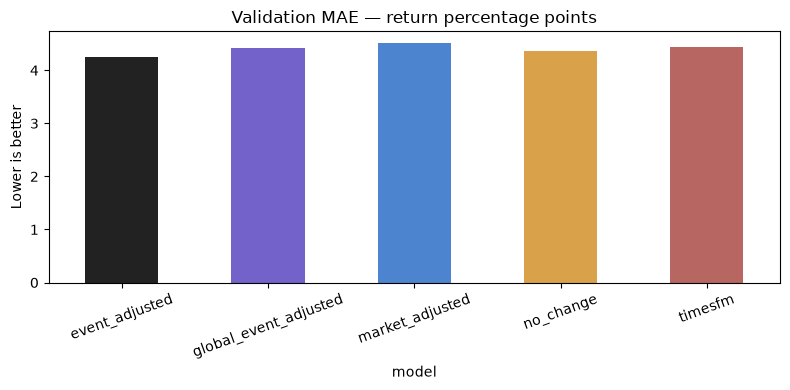

In [9]:
report = run_experiment(DATA, CONFIG, RUN, include_events=True,
                        data_kind='synthetic_verification_only' if MODE == 'synthetic_verification' else 'real')
predictions = pd.read_parquet(RUN/'predictions.parquet')
metrics = summarize(predictions)
display(metrics)
ax = metrics.set_index('model').mae_return_pp.plot.bar(figsize=(8,4), color=['#222222','#7262c9','#4c84cf','#d9a24a','#b86661'], title='Validation MAE — return percentage points')
ax.set_ylabel('Lower is better'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 7. Check the result and its uncertainty

Mean absolute error is measured in return percentage points. Lower is better. Read each fold separately, then look at individual companies; an average improvement can hide a failure on one asset.

We compare country-linked events with both market-only and global-event adjustments. Bootstrap blocks keep the companies together and use consecutive exchange sessions; blocks cannot jump across missing dates. The method reports an interval only with enough observations.

A positive estimated reduction in error is encouraging, but an interval crossing zero is inconclusive. These comparisons are exploratory and related, not a collection of independent confirmatory tests. Neither a correlation nor an improvement in prediction identifies a causal effect.

2025-09-01 to 2026-01-01


,model,dates,mae_return_pp,direction_accuracy
0,event_adjusted,80,3.779026,0.55625
1,global_event_adjusted,80,3.776737,0.58125
2,market_adjusted,80,3.941498,0.47500
3,no_change,80,3.630060,0.00000
4,timesfm,80,3.654740,0.43750


event_vs_market


,result
status,computed
dates,80
block_sessions,20
valid_blocks,61
mean_improvement_pp,0.162472
ci95_pp,"[0.003023, 0.662395]"
interpretation,Positive favors candidate; dependence-aware in...


exposure_vs_global


...

event_vs_market


,result
status,computed
dates,118
block_sessions,20
valid_blocks,99
mean_improvement_pp,0.331916
ci95_pp,"[-0.273606, 1.064713]"
interpretation,Positive favors candidate; dependence-aware in...


exposure_vs_global


,result
status,computed
dates,118
block_sessions,20
valid_blocks,99
mean_improvement_pp,0.307759
ci95_pp,"[-0.470542, 0.976719]"
interpretation,Positive favors candidate; dependence-aware in...


model,event_adjusted,global_event_adjusted,market_adjusted,no_change,timesfm
symbol,,,,,
AAPL,2.901586,2.817687,2.849548,2.718834,2.907814
FCX,5.588447,6.037320,6.167392,6.012223,5.952266


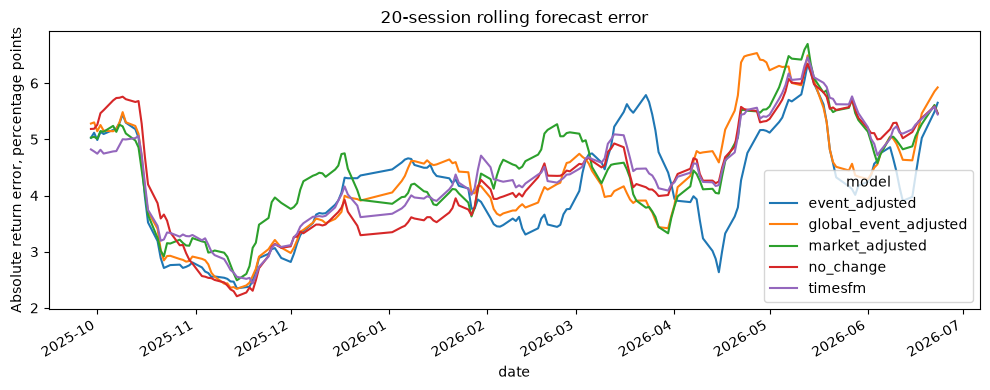

Missing event archive dates: ['2025-06-14', '2025-06-15', '2025-06-16', '2025-06-17', '2025-06-18', '2025-06-19', '2025-06-20', '2025-06-21', '2025-06-22', '2025-06-23', '2025-06-24', '2025-06-25', '2025-06-26', '2025-06-27', '2025-06-28', '2025-06-29', '2025-06-30', '2025-07-01']


,sum_over_archive_days
rows,70829600
missing_actor_countries,16937895
missing_source_urls,0
unique_source_urls,14364711


Summed daily URL counts are not a global unique-source or corroboration count.
Recent examples for manual source review — not yet reviewed, not a representative precision estimate:


,symbol,event_code,actor1_country,actor2_country,source_url,review_status
0,AAPL,163,NaN,CHN,https://www.niagarafallsreview.ca/business/bei...,not_reviewed
1,AAPL,163,NaN,CHN,https://www.niagarafallsreview.ca/business/bei...,not_reviewed
2,AAPL,163,CHN,CHN,https://www.niagarafallsreview.ca/business/bei...,not_reviewed
3,FCX,173,NaN,USA,https://www.klif.com/2026/10/20/newborn-found-...,not_reviewed
4,FCX,173,NaN,USA,https://www.wxow.com/news/la-crosse/la-crosse-...,not_reviewed
5,FCX,173,NaN,USA,https://chisagocountypress.com/news/2026/oct/2...,not_reviewed


In [10]:
for fold in report['folds']:
    print(fold['start'], 'to', fold['end'])
    display(pd.DataFrame(fold['metrics'])[['model','dates','mae_return_pp','direction_accuracy']])
    for comparison, values in fold.get('comparisons', {'event_vs_market':fold['uncertainty']}).items():
        print(comparison)
        display(pd.Series(values).to_frame('result'))
per_asset = predictions.assign(absolute_error_pp=lambda x: abs(x.predicted_return-x.target_return)*100).groupby(['symbol','model']).absolute_error_pp.mean().unstack()
display(per_asset)
loss = predictions.assign(absolute_error_pp=lambda x: abs(x.predicted_return-x.target_return)*100)
ax = loss.groupby(['date','model']).absolute_error_pp.mean().unstack().rolling(20).mean().plot(figsize=(10,4), title='20-session rolling forecast error')
ax.set_ylabel('Absolute return error, percentage points'); plt.tight_layout(); plt.show()
quality = json.loads((RUN/'quality.json').read_text())
print('Missing event archive dates:', quality.get('missing_archive_days', []))
if (DATA/'exposure-audit.json').exists():
    source_audit = json.loads((DATA/'exposure-audit.json').read_text())
    daily_quality = pd.DataFrame(source_audit['archive_quality'])
    display(daily_quality[['rows','missing_actor_countries','missing_source_urls','unique_source_urls']].sum().to_frame('sum_over_archive_days'))
    print('Summed daily URL counts are not a global unique-source or corroboration count.')
if (DATA/'event-relevance-review.csv').exists():
    review = pd.read_csv(DATA/'event-relevance-review.csv')
    print('Recent examples for manual source review — not yet reviewed, not a representative precision estimate:')
    display(review[['symbol','event_code','actor1_country','actor2_country','source_url','review_status']].head(6))

## 8. Save the model and check that we can use it again

We save the fitted column selection, missing-value handling and adjustment model together. The bundle also records the feature configuration and training dates. Reloading it should reproduce the predictions we just evaluated; the assertion below checks that.

For later use, `predict(prices, events, baselines)` builds the same features and adds the learned adjustment to the supplied TimesFM forecast. Collectors, the feature-building code and the pinned TimesFM model remain dependencies; this file is not the entire application.

The saved model was fitted on the last validation fold's training rows. We have not quietly trained it again on the evaluation outcomes. Only load trusted joblib files and use the matching environment recorded with the run.

In [11]:
bundle = load_bundle(RUN/'event_adjusted')
last_start, last_end = CONFIG['validation_windows'][-1]
_, last_test = chronological_split(eligible, last_start, last_end)
restored = bundle.predict_features(last_test)
recorded = predictions[(predictions.fold == len(CONFIG['validation_windows'])-1) & (predictions.model == 'event_adjusted')]
np.testing.assert_allclose(restored, recorded.predicted_return.to_numpy())
latest = bundle.predict(prices, events, baselines)
display(latest)
latest.to_parquet(RUN/'latest-research-predictions.parquet', index=False)
print('PASS: reloaded preprocessing + model reproduces saved evaluation predictions.')
print('Saved artifact:', RUN/'event_adjusted/pipeline.joblib')

,symbol,date,target_date,predicted_return,predicted_price
978,AAPL,2026-10-21,2026-10-28,0.005026,345.719027
979,FCX,2026-10-21,2026-10-28,0.024942,70.618517


PASS: reloaded preprocessing + model reproduces saved evaluation predictions.
Saved artifact: /Users/sumitsharma/Documents/ChatGPT/YodaX/data/research-runs/notebook-exposure_study-20261023T111657803314Z/event_adjusted/pipeline.joblib


## 9. What this experiment can tell us

We now have a more specific connection between events and companies, a longer evaluation, and an inspectable source trail. That improves the experiment’s design; it does not guarantee a better forecast.

If the country-linked model loses to TimesFM or does not reliably beat the simpler adjustment, we keep the simpler model. The next data improvements should focus on specific production interruptions, policy provisions and exposure amounts, with original-source corroboration. We still need the earlier historical backfill and sourced coverage for the other stocks and commodity benchmarks.

The present country lists are manually reviewed disclosure snapshots, not an automatically maintained supply-chain graph. They may become stale. Broad event codes remain noisy, and missing archives remove usable windows. These limitations belong beside the results.

Causation remains a separate research question. We would need a defined intervention and a credible comparison for what would have happened without it. No part of this notebook establishes that a country event caused a stock return.

Sources: [Apple 2024 filing](https://www.sec.gov/Archives/edgar/data/320193/000032019324000123/aapl-20240928.htm), [Freeport 2024 filing](https://www.sec.gov/Archives/edgar/data/831259/000083125925000006/fcx-20241231.htm), [GDELT](https://gdeltproject.org/data.html), [CAMEO codebook](https://parusanalytics.com/eventdata/cameo.dir/CAMEO.CDB.09b5.pdf), [TimesFM](https://github.com/google-research/timesfm).

In the expanded real run, country-linked features were essentially tied with global events in late 2025 and had lower observed error in the first half of 2026. Both intervals for their improvement over global events included zero. That is a mixed, inconclusive result, not a production recommendation. The tables above remain the record if you rerun the experiment.